# PDFT Calculation for H$_2$

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

In [2]:
# define geometry
sep = 1.4

mol = fgto.M(atom=f"""
    H {-0.5*sep} 0 0
    H {+0.5*sep} 0 0
""", unit='bohr', basis='cc-pvdz',
    fragments={0: [0], 1: [1]},  # atom indices (1-based) of each fragment
    ensembles={'spin': [0, 1]})  # spin ensemble on fragments 1 and 2

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -1.15988035


---
## Do PDFT Calculations

### Inversion Method

In [3]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=20, frag_symm='dimer')
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

frag_symm: 2 operations; fragments solved: [0] of 2
P-DFT method=inversion xc=PBE fxc=PBE nao=10 grid=70352
  it    1  Ef =    -0.9974082801  dEf =         nan  |dVp| = 4.088e-01
  it    2  Ef =    -0.9836765854  dEf =   1.373e-02  |dVp| = 2.350e-01
  it    3  Ef =    -0.9682415069  dEf =   1.544e-02  |dVp| = 1.524e-01
  it    4  Ef =    -0.9587431975  dEf =   9.498e-03  |dVp| = 1.159e-01
  it    5  Ef =    -0.9534673920  dEf =   5.276e-03  |dVp| = 1.009e-01
  it    6  Ef =    -0.9506018856  dEf =   2.866e-03  |dVp| = 9.481e-02
  it    7  Ef =    -0.9490383934  dEf =   1.563e-03  |dVp| = 9.210e-02
  it    8  Ef =    -0.9481670252  dEf =   8.714e-04  |dVp| = 9.075e-02
  it    9  Ef =    -0.9476616138  dEf =   5.054e-04  |dVp| = 8.998e-02
  it   10  Ef =    -0.9473497300  dEf =   3.119e-04  |dVp| = 8.947e-02
  it   11  Ef =    -0.9471391353  dEf =   2.106e-04  |dVp| = 8.909e-02
  it   12  Ef =    -0.9469806065  dEf =   1.585e-04  |dVp| = 8.877e-02
  it   13  Ef =    -0.9468477202  dEf = 

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 20 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Functional Method

In [4]:
mf2 = pdft.RKS(mol, method='functional-T', maxiter=20, frag_symm='dimer')
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}")

frag_symm: 2 operations; fragments solved: [0] of 2
P-DFT method=functional xc=PBE fxc=PBE nao=10 grid=70352
  it    1  Ef =    -0.9974082801  dEf =         nan  |dVp| = 4.097e-01
  it    2  Ef =    -0.9815403235  dEf =   1.587e-02  |dVp| = 1.746e-01
  it    3  Ef =    -0.9665744370  dEf =   1.497e-02  |dVp| = 1.112e-01
  it    4  Ef =    -0.9594465839  dEf =   7.128e-03  |dVp| = 1.104e-01
  it    5  Ef =    -0.9564977804  dEf =   2.949e-03  |dVp| = 1.142e-01
  it    6  Ef =    -0.9553218134  dEf =   1.176e-03  |dVp| = 1.152e-01
  it    7  Ef =    -0.9548343308  dEf =   4.875e-04  |dVp| = 1.147e-01
  it    8  Ef =    -0.9545982780  dEf =   2.361e-04  |dVp| = 1.137e-01
  it    9  Ef =    -0.9544480904  dEf =   1.502e-04  |dVp| = 1.124e-01
  it   10  Ef =    -0.9543238129  dEf =   1.243e-04  |dVp| = 1.112e-01
  it   11  Ef =    -0.9542050282  dEf =   1.188e-04  |dVp| = 1.101e-01
  it   12  Ef =    -0.9540854547  dEf =   1.196e-04  |dVp| = 1.091e-01
  it   13  Ef =    -0.9539636171  dEf =

### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=30, frag_symm='dimer')
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

frag_symm: 2 operations; fragments solved: [0] of 2
P-DFT method=reference xc=PBE fxc=PBE nao=10 grid=70352
  it    1  Ef =    -0.9974082801  dEf =         nan  |dVp| = 4.215e-02  L1 = 5.141e-01
  it    2  Ef =    -0.9967241231  dEf =   6.842e-04  |dVp| = 3.687e-02  L1 = 4.472e-01
  it    3  Ef =    -0.9952823452  dEf =   1.442e-03  |dVp| = 3.281e-02  L1 = 3.967e-01
  it    4  Ef =    -0.9935815645  dEf =   1.701e-03  |dVp| = 2.959e-02  L1 = 3.572e-01
  it    5  Ef =    -0.9918374721  dEf =   1.744e-03  |dVp| = 2.696e-02  L1 = 3.254e-01
  it    6  Ef =    -0.9901444707  dEf =   1.693e-03  |dVp| = 2.477e-02  L1 = 2.993e-01
  it    7  Ef =    -0.9885419425  dEf =   1.603e-03  |dVp| = 2.291e-02  L1 = 2.775e-01
  it    8  Ef =    -0.9870433481  dEf =   1.499e-03  |dVp| = 2.132e-02  L1 = 2.589e-01
  it    9  Ef =    -0.9856497100  dEf =   1.394e-03  |dVp| = 1.993e-02  L1 = 2.430e-01
  it   10  Ef =    -0.9843564265  dEf =   1.293e-03  |dVp| = 1.872e-02  L1 = 2.293e-01
  it   11  Ef =    -0.

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 30 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot densities and partition potential

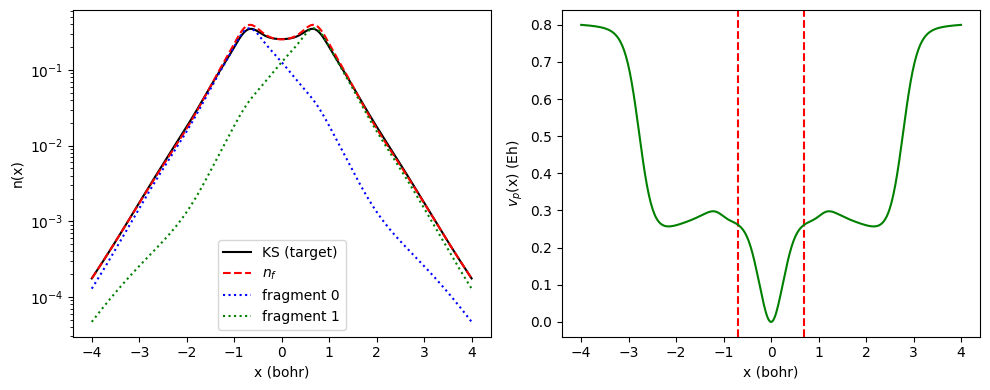

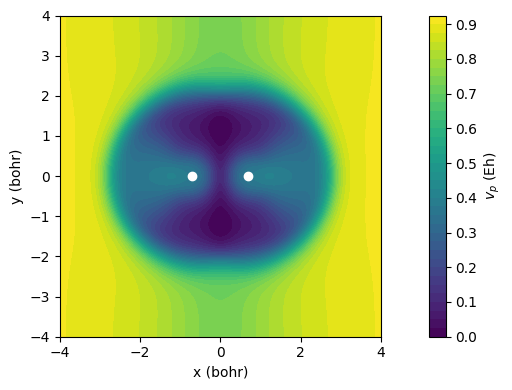

In [6]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_0 = mf1.eval_density(line, frag=0)            # fragment densities
n_1 = mf1.eval_density(line, frag=1)
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()